# Notebook 01 – Data Loading and Inspection

## What is this notebook for?
This is the first step of the machine learning project.  
We load the raw data from the World Food Programme (WFP) and check that it loaded correctly.

## Why do we need this stage?
- If the data is not loaded properly, every later step will fail.
- We must confirm the number of rows, columns, data types, and date range.
- We must record where the data came from so that anyone can repeat the work.


## Step 1.1 – Import the libraries we need
We import pandas (for tables), numpy (for numbers), and matplotlib/seaborn (for plots).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully.")


Libraries imported successfully.


## Step 1.2 – Load the raw CSV file
The data comes from the WFP Food Prices database for Uganda.  
We use a relative path so the notebook works on any computer.


In [2]:
raw_path = Path('../data/raw/wfp_food_prices_uga.csv')
df = pd.read_csv(raw_path)
df['date'] = pd.to_datetime(df['date'])

print("Data loaded successfully.")
print("Shape of the data (rows, columns):", df.shape)


Data loaded successfully.
Shape of the data (rows, columns): (34328, 16)


### What the result means
The shape tells us how many rows (observations) and columns (features) we have.  
A large number of rows is good because it gives the models more examples to learn from.


## Step 1.3 – Look at the first and last few rows
This helps us see if the header was read correctly and if there are any strange values at the bottom.


In [3]:
print("=== First 5 rows ===")
print(df.head().to_string())
print("\n=== Last 5 rows ===")
print(df.tail().to_string())


=== First 5 rows ===
        date   admin1             admin2 market  market_id  latitude  longitude            category commodity  commodity_id unit priceflag  pricetype currency    price  usdprice
0 2006-01-15    Busia        Samia-bugwe  Busia       2665      0.47      34.09  cereals and tubers     Maize            51   KG    actual  Wholesale      UGX   298.40      0.17
1 2006-01-15  Kampala    Central Kampala  Owino        258      0.32      32.57  cereals and tubers     Maize            51   KG    actual  Wholesale      UGX   345.42      0.20
2 2006-01-15  Kampala    Central Kampala  Owino        258      0.32      32.57  cereals and tubers      Rice            52   KG    actual  Wholesale      UGX  1013.40      0.58
3 2006-01-15     Lira  Lira Municipality   Lira        263      2.23      32.91  cereals and tubers     Maize            51   KG    actual  Wholesale      UGX   247.76      0.14
4 2006-02-15    Busia        Samia-bugwe  Busia       2665      0.47      34.09  cereals 

## Step 1.4 – Check column names and data types
We need to know which columns are numbers and which are text.


In [4]:
print("Column names:")
print(df.columns.tolist())
print("\n=== Data types ===")
print(df.dtypes)
print("\n=== Basic info ===")
df.info()


Column names:
['date', 'admin1', 'admin2', 'market', 'market_id', 'latitude', 'longitude', 'category', 'commodity', 'commodity_id', 'unit', 'priceflag', 'pricetype', 'currency', 'price', 'usdprice']

=== Data types ===
date            datetime64[us]
admin1                     str
admin2                     str
market                     str
market_id                int64
latitude               float64
longitude              float64
category                   str
commodity                  str
commodity_id             int64
unit                       str
priceflag                  str
pricetype                  str
currency                   str
price                  float64
usdprice               float64
dtype: object

=== Basic info ===
<class 'pandas.DataFrame'>
RangeIndex: 34328 entries, 0 to 34327
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          34328 non-null  datetime64[us]
 1 

## Step 1.5 – Check the date range and basic statistics
Knowing the start and end date tells us how many years of history we have.


In [5]:
print("Earliest date:", df['date'].min().date())
print("Latest date  :", df['date'].max().date())
print("\nNumber of unique markets:", df['market'].nunique())
print("Number of unique commodities:", df['commodity'].nunique())
print("\n=== Price summary ===")
print(df['price'].describe())


Earliest date: 2006-01-15
Latest date  : 2026-08-15

Number of unique markets: 43
Number of unique commodities: 38

=== Price summary ===
count    34328.000000
mean      3188.824076
std       3747.237874
min          2.000000
25%       1200.000000
50%       2000.000000
75%       3563.000000
max      66608.000000
Name: price, dtype: float64


## Step 1.6 – Graph 1: Number of records per commodity (top 15)
This chart shows which food items appear most often in the data.


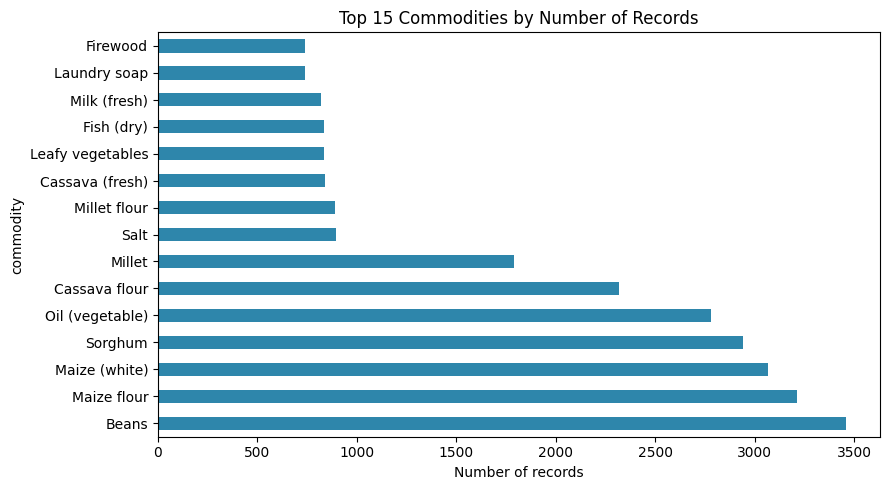

In [6]:
plt.figure(figsize=(9, 5))
top_comm = df['commodity'].value_counts().head(15)
top_comm.plot(kind='barh', color='#2E86AB')
plt.title('Top 15 Commodities by Number of Records')
plt.xlabel('Number of records')
plt.tight_layout()
plt.savefig('../figures/01_top_commodities.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 1.7 – Graph 2: Number of records per market (top 15)
This chart helps us see which markets have the most observations.


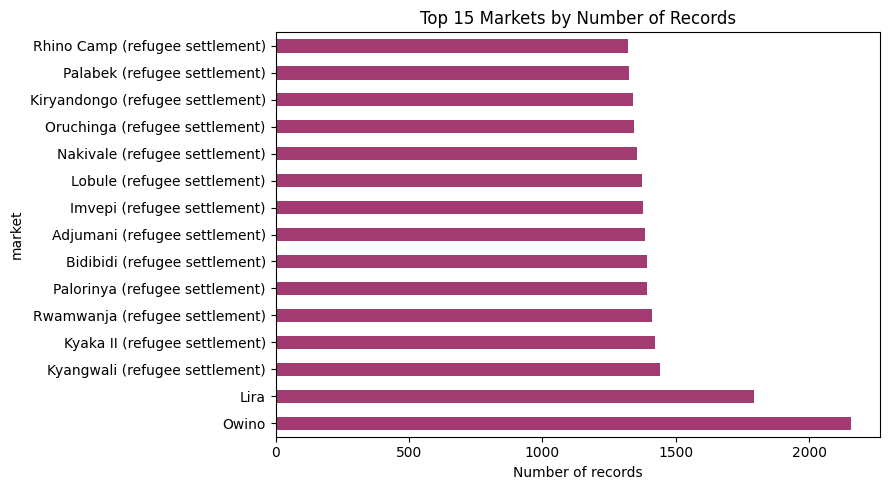

In [7]:
plt.figure(figsize=(9, 5))
top_mkt = df['market'].value_counts().head(15)
top_mkt.plot(kind='barh', color='#A23B72')
plt.title('Top 15 Markets by Number of Records')
plt.xlabel('Number of records')
plt.tight_layout()
plt.savefig('../figures/01_top_markets.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 1.8 – Graph 3: Price type distribution
Most of the data is Retail. We will keep only Retail prices later.


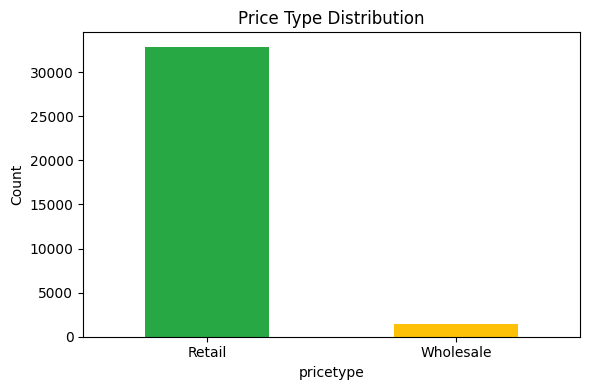

In [8]:
plt.figure(figsize=(6, 4))
df['pricetype'].value_counts().plot(kind='bar', color=['#28A745', '#FFC107'])
plt.title('Price Type Distribution')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/01_price_type.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 1.9 – Record the data source


In [9]:
print("=" * 60)
print("DATA SOURCE INFORMATION")
print("=" * 60)
print("Source     : World Food Programme (WFP) Food Prices Database")
print("Country    : Uganda")
print("Download   : https://data.humdata.org/dataset/wfp-food-prices-for-uganda")
print("File name  : wfp_food_prices_uga.csv")
print("Coverage   : 2006 to 2026")
print("Unit       : Ugandan Shillings (UGX) per kilogram")
print("=" * 60)


DATA SOURCE INFORMATION
Source     : World Food Programme (WFP) Food Prices Database
Country    : Uganda
Download   : https://data.humdata.org/dataset/wfp-food-prices-for-uganda
File name  : wfp_food_prices_uga.csv
Coverage   : 2006 to 2026
Unit       : Ugandan Shillings (UGX) per kilogram
